**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso:** TC5061 - Operaciones de aprendizaje automático

Tecnológico de Monterrey

Dr. Iván Reyes-Amezcua

**Semana 4**
Código de experimentación base con MLflow — Notebook de exploración

---

*   NOMBRE: Carlos David Martínez Calva
*   MATRÍCULA: A01056864

## Objetivo del notebook

Este notebook se conserva **únicamente para la exploración de datos** del dataset **IMDB (películas y series)**. Proviene del notebook baseline de la Semana 3; la limpieza, el entrenamiento, la evaluación y el registro en MLflow se migraron al paquete `imdb_rating` para que sean reproducibles y ejecutables desde la línea de comandos.

| Paso | Etapa | Dónde vive |
|---|---|---|
| 1 | Carga y descripción del dataset | Este notebook |
| 2 | Análisis exploratorio (EDA) | Este notebook |
| 3 | Limpieza de datos | `imdb_rating/dataset.py` (`limpiar`) |
| 4 | Preprocesamiento y modelo | `imdb_rating/features.py`, `imdb_rating/modeling/train.py` |
| 5 | Evaluación y registro en MLflow | `imdb_rating/modeling/train.py` |

**Problema a resolver:** predecir la calificación promedio de IMDB (`rating`, escala 1–10) de un título a partir de sus características (duración, número de votos, año, clasificación, géneros y tipo de título). Al ser una variable continua, se trata de un **problema de regresión supervisada**.

### Librerías y configuración

La ruta del dataset se toma de `imdb_rating.config` (misma fuente que usa el script de entrenamiento) y la semilla se fija en un solo lugar para que los muestreos del EDA sean reproducibles.

> Requiere el paquete instalado: `pip install -r requirements.txt` desde la raíz del proyecto.

In [1]:
# --- Manipulación de datos ---
import warnings

import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Código del proyecto: una sola fuente para rutas y conversión de tipos ---
from imdb_rating.config import RAW_DATA_FILE
from imdb_rating.dataset import convertir_tipos

# --- Configuración general ---
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110

DATA_PATH = RAW_DATA_FILE   # data/raw/IMBD.csv
RANDOM_STATE = 42           # semilla para los muestreos del EDA

print(f'pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}')

pandas 3.0.6 | numpy 2.5.3 | seaborn 0.13.2


---
## Paso 1. Carga y descripción del dataset

**Fuente:** [IMDB Dataset — Kaggle (payamamanat)](https://www.kaggle.com/datasets/payamamanat/imbd-dataset), archivo `IMBD.csv`. Contiene títulos listados en IMDB (películas, series, episodios y especiales de TV) con su calificación promedio, número de votos y metadatos descriptivos.

### 1.1 Carga de los datos

In [2]:
# Lectura del CSV original; se conserva una copia intacta (df_raw) para poder
# comparar el antes y el después de la limpieza
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print(f'Registros: {df.shape[0]:,} | Variables: {df.shape[1]}')
df.sample(7, random_state=RANDOM_STATE)

Registros: 9,957 | Variables: 9


,title,year,certificate,duration,genre,rating,description,stars,votes
3905,Rock My Heart,(2017),TV-PG,105 min,Drama,6.5,17-year-old Jana has a congenital heart defect. To defy ...,"['Hanno Olderdissen', '| ', ' Stars:', 'Emilio Sakray...","1,032"
4850,VeggieTales in the House,(2014–2016),TV-Y,NaN,"Animation, Short, Adventure",4.0,Get ready to love your veggies! The beloved faith-based ...,"['Phil Vischer, ', 'Mike Nawrocki, ', 'Tress MacNeille, ...",319
6369,Irredeemable,NaN,NaN,NaN,"Action, Comedy, Sci-Fi",NaN,A beloved superhero turns on the world he formerly prote...,['Jeymes Samuel'],NaN
2769,Transformers: Robots in Disguise,(2014–2020),TV-Y7,22 min,"Animation, Action, Adventure",5.9,"When a new army of Decepticons appear, Bumblebee must le...","['Khary Payton, ', 'Mitchell Whitfield, ', 'Will Friedle...","1,091"
3755,Inspector Gadget,(2015–2018),TV-Y7,22 min,"Animation, Action, Adventure",4.5,"When Dr. Claw returns, Inspector Gadget is brought out o...","['Ivan Sherry, ', 'Tara Strong, ', 'Martin Roach, ', 'Sc...",638
7905,Exam Time Rap Song ft. Jordindian,(2020),NaN,NaN,"Short, Music",NaN,Add a Plot,['Sahit Anand'],NaN
6765,L'oro di Scampia,(2014 TV Movie),NaN,102 min,"Biography, Drama",6.8,"In Scampia, the Camorra hires young people from an early...","['Marco Pontecorvo', '| ', ' Stars:', 'Giuseppe Fiore...",107


### 1.2 Estructura: tipos de dato y valores no nulos

In [3]:
# Resumen técnico de pandas: tipo inferido y conteo de no nulos por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9957 entries, 0 to 9956
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   title        9957 non-null   str    
 1   year         9430 non-null   str    
 2   certificate  6504 non-null   str    
 3   duration     7921 non-null   str    
 4   genre        9884 non-null   str    
 5   rating       8784 non-null   float64
 6   description  9957 non-null   str    
 7   stars        9957 non-null   str    
 8   votes        8784 non-null   str    
dtypes: float64(1), str(8)
memory usage: 3.5 MB


In [4]:
# Tabla resumen por variable: tipo, faltantes, cardinalidad y un ejemplo real
resumen = pd.DataFrame({
    'tipo_pandas': df.dtypes.astype(str),
    'no_nulos': df.notna().sum(),
    'nulos': df.isna().sum(),
    '%_nulos': (df.isna().mean() * 100).round(1),
    'valores_unicos': df.nunique(),
    'ejemplo': df.apply(lambda col: col.dropna().iloc[0]),
})
resumen

,tipo_pandas,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
title,str,9957,0,0.0,7912,Cobra Kai
year,str,9430,527,5.3,498,(2018– )
certificate,str,6504,3453,34.7,20,TV-14
duration,str,7921,2036,20.4,291,30 min
genre,str,9884,73,0.7,569,"Action, Comedy, Drama"
rating,float64,8784,1173,11.8,79,8.5
description,str,9957,0,0.0,9433,Decades after their 1984 All Valley Karate Tournament bo...
stars,str,9957,0,0.0,8615,"['Ralph Macchio, ', 'William Zabka, ', 'Courtney Henggel..."
votes,str,8784,1173,11.8,4862,"177,031"


### 1.3 Diccionario de datos

| Variable | Significado | Tipo en el CSV | Tipo real esperado | Observaciones |
|---|---|---|---|---|
| `title` | Nombre del título | texto | categórica (identificador) | Se repite en los episodios de una misma serie |
| `year` | Año o periodo de emisión | texto | numérica (año) | Mezcla formatos: `(2020)`, `(2016– )`, `(2014–2015)`, `(2018 TV Special)`, `(II)`. El guion indica serie de TV |
| `certificate` | Clasificación por edad | texto | categórica | ~35 % faltante; mezcla sistemas de cine (`R`, `PG-13`) y de TV (`TV-MA`, `TV-14`) |
| `duration` | Duración por episodio o película | texto (`"46 min"`) | numérica (minutos) | Requiere extraer el número |
| `genre` | Lista de hasta 3 géneros | texto separado por comas | multietiqueta | Ej. `"Action, Crime, Drama"` |
| `rating` | Calificación promedio de usuarios (1–10) | numérica | numérica | **Variable objetivo.** ~12 % faltante |
| `description` | Sinopsis | texto libre | texto | No se usará en el baseline (requiere NLP) |
| `stars` | Director(es) y elenco principal | texto con forma de lista | texto | Formato irregular: a veces incluye el separador `'\| Stars:'` |
| `votes` | Número de votos de usuarios | texto (`"145,893"`) | numérica entera | Separador de miles; faltante exactamente en las mismas filas que `rating` |

**Primeras observaciones de calidad**, que se tratarán en el Paso 3:

- Solo `rating` está tipada como numérica; `year`, `duration` y `votes` son numéricas pero llegaron como texto.
- Existen valores faltantes relevantes en `certificate`, `duration`, `rating`/`votes` y `year`.
- El dataset mezcla **películas, series y episodios individuales**, lo que generará títulos repetidos que no necesariamente son duplicados.

---
## Paso 2. Análisis exploratorio de datos (EDA)

### 2.1 Preparación de tipos para poder explorar

Tres variables numéricas llegaron como texto (`duration`, `votes`, `year`). Sin convertirlas no es posible ver su distribución ni su relación con `rating`, por lo que **la conversión de tipo se hace aquí, en el EDA**.

**Decisión: convertir ≠ limpiar.** En este punto solo se cambia el tipo de dato; los valores faltantes **se conservan como `NaN`**. Imputar, eliminar o recortar valores se decide en el Paso 3, una vez que el EDA haya mostrado cómo se comportan los datos.

La lógica vive en `imdb_rating/dataset.py` (`convertir_tipos`) y se importa aquí: el notebook y el script de entrenamiento usan **exactamente la misma función**, sin código duplicado.

**Reglas de conversión:**

| Columna original | Columna(s) nueva(s) | Regla |
|---|---|---|
| `duration` (`"46 min"`) | `duracion_min` | Extraer el número entero |
| `votes` (`"145,893"`) | `votos` | Quitar el separador de miles |
| `year` (`"(2014–2015)"`, `"(I) (2019 TV Movie)"`…) | `anio_inicio`, `anio_fin` | Primer y segundo año de 4 dígitos |
| | `es_serie` | El periodo contiene un guion (`–`) |
| | `en_emision` | El guion no tiene año de cierre: `(2016– )` |
| | `tipo_titulo` | `Serie`, `TV Special`, `TV Movie`, `Video`, `TV Short`, otros, o `Película` si no hay guion ni etiqueta |

Los números romanos `(I)`, `(II)`… **no son ediciones**: IMDb los usa para distinguir títulos homónimos (p. ej. varios *It* o *Titans*). No aportan información predictiva y se descartan; el año que los acompaña sí se conserva.

In [5]:
df = convertir_tipos(df_raw)
cols_nuevas = ['duracion_min', 'votos', 'anio_inicio', 'anio_fin', 'es_serie', 'en_emision', 'tipo_titulo']
df[['year', 'duration', 'votes'] + cols_nuevas].sample(8, random_state=RANDOM_STATE)

,year,duration,votes,duracion_min,votos,anio_inicio,anio_fin,es_serie,en_emision,tipo_titulo
3905,(2017),105 min,"1,032",105.0,1032.0,2017.0,NaN,False,False,Película
4850,(2014–2016),NaN,319,NaN,319.0,2014.0,2016.0,True,False,Serie
6369,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,Película
2769,(2014–2020),22 min,"1,091",22.0,1091.0,2014.0,2020.0,True,False,Serie
3755,(2015–2018),22 min,638,22.0,638.0,2015.0,2018.0,True,False,Serie
7905,(2020),NaN,NaN,NaN,NaN,2020.0,NaN,False,False,Película
6765,(2014 TV Movie),102 min,107,102.0,107.0,2014.0,NaN,False,False,TV Movie
3787,(2020),90 min,"1,080",90.0,1080.0,2020.0,NaN,False,False,Película


In [6]:
# Verificación: la conversión no debe crear ni ocultar faltantes.
# Cada columna nueva debe tener exactamente los mismos NaN que su columna de origen.
assert df['duracion_min'].isna().equals(df_raw['duration'].isna()), 'duration perdió o creó NaN'
assert df['votos'].isna().equals(df_raw['votes'].isna()), 'votes perdió o creó NaN'

sin_anio = df['anio_inicio'].isna().sum()
print(f'year faltante en el original: {df_raw["year"].isna().sum()}')
print(f'year sin año de 4 dígitos tras convertir: {sin_anio} '
      f'(incluye ~{sin_anio - df_raw["year"].isna().sum()} filas solo con número romano o etiqueta)')
print()
print(df['tipo_titulo'].value_counts().to_string())

year faltante en el original: 527
year sin año de 4 dígitos tras convertir: 631 (incluye ~104 filas solo con número romano o etiqueta)

tipo_titulo
Película          5509
Serie             3589
TV Special         480
TV Movie           185
Video              163
TV Short            14
Podcast Series      11
Music Video          4
Video Game           2


#### ¿Por qué no rellenar los faltantes con 0?

Algunos notebooks públicos de este dataset reemplazan los `NaN` de `duration` por `0` antes de convertir. Se compara el efecto contra conservar `NaN`:

,Conservar NaN,Imputar 0
count,7921.0,9957.0
mean,73.8,58.7
std,50.3,53.8
min,1.0,0.0
25%,42.0,22.0
50%,67.0,52.0
75%,98.0,93.0
max,990.0,990.0


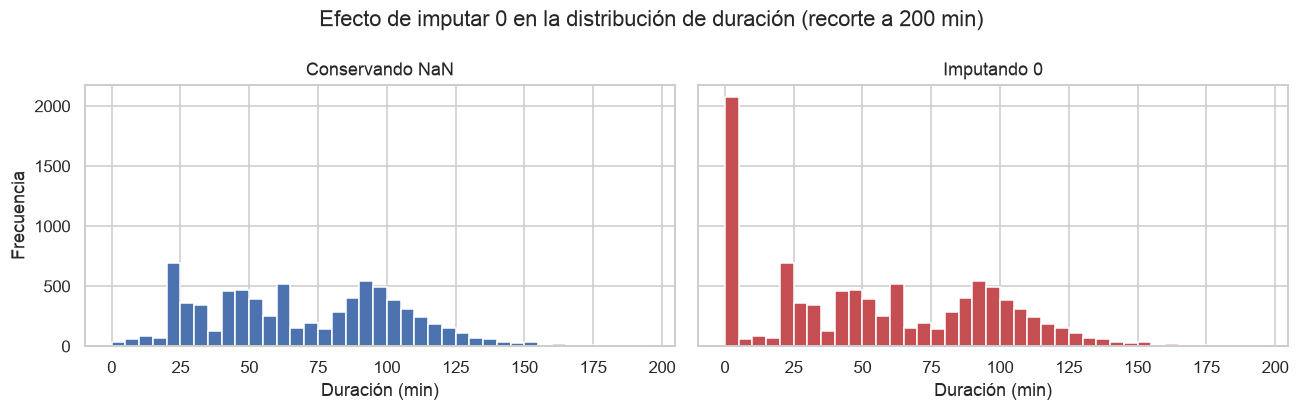

In [7]:
# Comparación: conservar NaN vs. imputar 0 (lo que hace el notebook de referencia de Kaggle)
dur_nan = df['duracion_min']
dur_cero = df['duracion_min'].fillna(0)

comparacion = pd.DataFrame({
    'Conservar NaN': dur_nan.describe(),
    'Imputar 0': dur_cero.describe(),
}).round(1)
display(comparacion)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
bins = np.arange(0, 200, 5)
axes[0].hist(dur_nan.dropna(), bins=bins, color='C0')
axes[0].set_title('Conservando NaN')
axes[1].hist(dur_cero, bins=bins, color='C3')
axes[1].set_title('Imputando 0')
for ax in axes:
    ax.set_xlabel('Duración (min)')
axes[0].set_ylabel('Frecuencia')
fig.suptitle('Efecto de imputar 0 en la distribución de duración (recorte a 200 min)')
plt.tight_layout()
plt.show()

**Interpretación:** imputar 0 convierte ~20 % de los registros en títulos de "0 minutos", que no existen. Esto **desplaza la media y la mediana hacia abajo**, crea un pico artificial en el histograma y, si llegara al modelo, le enseñaría una relación falsa entre duración y calificación. Por eso los `NaN` se conservan durante el EDA.

#### `duracion_min`: valores extremos

¿Una duración de 990 minutos es un error de captura o un dato real?

In [8]:
# Títulos más largos: se revisan junto con su tipo para entender el valor extremo
df.nlargest(8, 'duracion_min')[['title', 'year', 'tipo_titulo', 'duracion_min', 'genre', 'rating']]

,title,year,tipo_titulo,duracion_min,genre,rating
943,The Vietnam War,(2017),Película,990.0,"Documentary, History, War",9.1
2116,The Time in Between,(2013–2014),Serie,853.0,"Adventure, Drama, History",8.3
989,The Staircase,(2004–2018),Serie,629.0,"Documentary, Crime, Drama",7.8
3681,The Innocence Files,(2020),Película,573.0,"Documentary, Crime",7.9
143,The Haunting of Hill House,(2018),Película,572.0,"Drama, Horror, Mystery",8.6
793,Cosmos: A Spacetime Odyssey,(2014),Película,557.0,Documentary,9.3
227,Maid,(2021),Película,545.0,Drama,8.4
1736,Dogs of Berlin,(2018– ),Serie,542.0,"Action, Crime, Drama",7.5


**Hallazgos:**

1. Los valores extremos **no son errores de captura**: son **miniseries o docuseries cuya duración registrada es el total** (p. ej. *The Vietnam War*, 990 min ≈ 10 episodios). En cambio, las series en emisión registran la **duración por episodio** (~20–60 min). Es decir, `duracion_min` **no tiene el mismo significado en todas las filas**.
2. Varias de esas miniseries (*The Vietnam War*, *The Haunting of Hill House*, *Maid*, *Cosmos*) quedaron clasificadas como `Película`, porque IMDb las registra con un solo año, sin guion. La regla basada en `year` **no distingue miniseries de películas**; es una limitación de la variable `tipo_titulo` que se documenta y se considerará en el tratamiento de outliers (Paso 3).

#### `votos`: ¿cómo visualizar una distribución tan asimétrica?

El mínimo es 5 votos y el máximo ~1.8 millones; la media (~19.5 mil) es más de 16 veces la mediana (~1.2 mil).

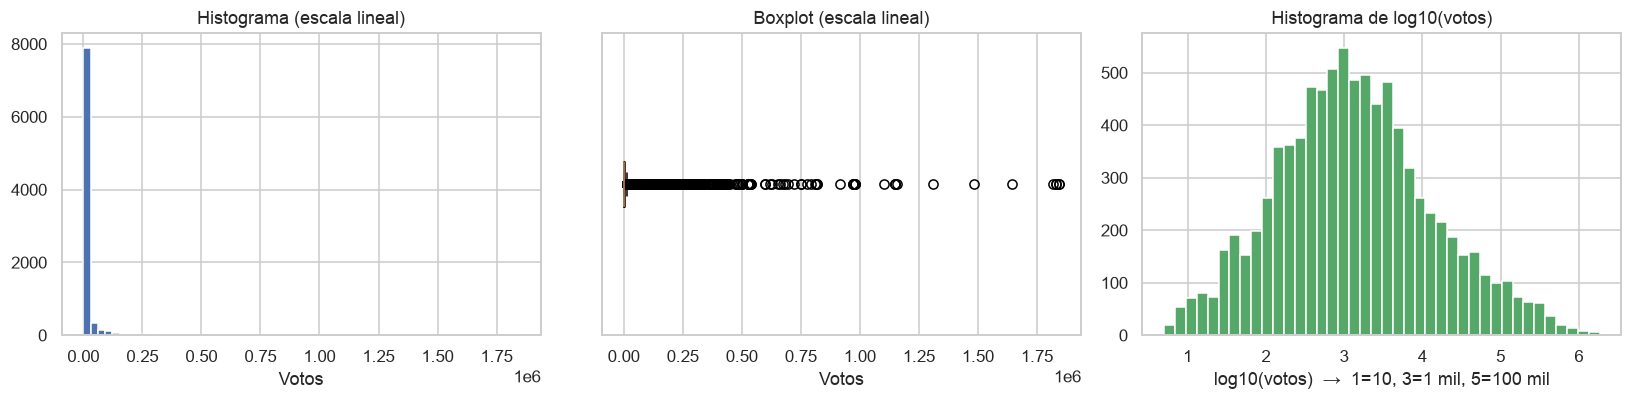

Media: 19,523 | Mediana: 1,187 | Asimetría (skew): 11.1 → log10: 0.25


In [9]:
# Tres formas de ver la misma variable: solo la escala logarítmica la hace legible
votos = df['votos'].dropna()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].hist(votos, bins=60, color='C0')
axes[0].set_title('Histograma (escala lineal)')
axes[0].set_xlabel('Votos')

axes[1].boxplot(votos, vert=False)
axes[1].set_title('Boxplot (escala lineal)')
axes[1].set_xlabel('Votos')
axes[1].set_yticks([])

axes[2].hist(np.log10(votos), bins=40, color='C2')
axes[2].set_title('Histograma de log10(votos)')
axes[2].set_xlabel('log10(votos)  →  1=10, 3=1 mil, 5=100 mil')
plt.tight_layout()
plt.show()

print(f'Media: {votos.mean():,.0f} | Mediana: {votos.median():,.0f} | '
      f'Asimetría (skew): {votos.skew():.1f} → log10: {np.log10(votos).skew():.2f}')

**Interpretación:** en escala lineal casi todo el histograma queda en la primera barra y el boxplot marca cientos de puntos como "outliers". No hay un outlier aislado, sino una **cola larga a la derecha**, típica de variables de popularidad: pocos títulos concentran la mayoría de los votos. Con `log10` la distribución se vuelve aproximadamente simétrica (skew cercano a 0). **Decisión:** en el EDA y en el modelo se usará `log10(votos)` y no se eliminarán los valores altos, porque son legítimos.

#### ¿Es igual de confiable un `rating` con pocos votos?

In [10]:
# Rating agrupado por rangos de votos: ¿cambia el nivel o la dispersión?
rangos = pd.cut(df['votos'], bins=[0, 100, 1_000, 10_000, 100_000, np.inf],
                labels=['≤100', '100–1k', '1k–10k', '10k–100k', '>100k'])
df.groupby(rangos, observed=True)['rating'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
votos,,,,,,
≤100,1092,6.85,7.0,1.18,2.5,9.4
100–1k,3010,6.64,6.8,1.24,1.7,9.6
1k–10k,3068,6.72,6.9,1.22,2.0,9.6
10k–100k,1221,6.86,6.9,1.16,2.6,9.9
>100k,393,7.50,7.6,0.93,5.2,9.5


**Interpretación:** la dispersión (`std` ≈ 1.2) es prácticamente la misma con menos de 100 votos que con 10 mil, así que no hay evidencia de que los ratings con pocos votos sean mucho más ruidosos. Lo que sí cambia es el **nivel**: los títulos con más de 100 mil votos promedian ~7.5 frente a ~6.7 del resto. Esto sugiere que la popularidad (`votos`) **sí es un predictor útil** del rating, y que no es necesario filtrar por un mínimo de votos en el baseline.

#### Filas sin `rating`: ¿qué son?

`rating` y `votes` faltan en exactamente las mismas 1,173 filas.

In [11]:
# Perfil de las filas sin variable objetivo
sin_rating = df[df['rating'].isna()]
print(f'Filas sin rating: {len(sin_rating):,} ({len(sin_rating) / len(df):.1%})')
print(f'Coinciden con votes faltante: {df["rating"].isna().equals(df["votos"].isna())}')
print(f'Sin sinopsis real ("Add a Plot"): {sin_rating["description"].str.contains("Add a Plot").mean():.1%}')
print('\nAño de inicio más frecuente en estas filas:')
print(sin_rating['anio_inicio'].value_counts().head(5).to_string())
sin_rating[['title', 'year', 'tipo_titulo', 'description']].head(5)

Filas sin rating: 1,173 (11.8%)
Coinciden con votes faltante: True
Sin sinopsis real ("Add a Plot"): 15.3%

Año de inicio más frecuente en estas filas:
anio_inicio
2022.0    207
2020.0     95
2021.0     57
2023.0     40
2019.0     29


,title,year,tipo_titulo,description
55,Guillermo del Toro's Pinocchio,(II) (2022),Película,A darker version of the classic children's fairy tale of...
65,The School for Good and Evil,(2022),Película,Best friends Sophie and Agatha find themselves on opposi...
67,Wednesday,(2022– ),Serie,"Follows Wednesday Addams' years as a student, when she a..."
80,Mr. Harrigan's Phone,(2022),Película,"When Mr. Harrigan dies, the teen who befriended and did ..."
209,Luckiest Girl Alive,(2022),Película,"A woman in New York, who seems to have things under cont..."


**Interpretación:** son principalmente **títulos aún no estrenados** al momento de la extracción de los datos (2022–2023, p. ej. *Wednesday*), por eso no tienen votos ni calificación; el 15 % ni siquiera tiene sinopsis. El rating de IMDb es el promedio ponderado de los votos de **usuarios**, así que sin votos no existe.

**Decisión:** se excluyen del análisis de la variable objetivo (pandas lo hace por defecto al ignorar `NaN`). Para el modelo **no se puede imputar la variable objetivo** (sería inventar la respuesta que se quiere predecir), por lo que en el Paso 3 se eliminarán del conjunto de modelado.

### 2.2 Estadísticas descriptivas

In [12]:
# log10(votos) se agrega como columna auxiliar del EDA por la asimetría vista en 2.1
df['log10_votos'] = np.log10(df['votos'])

num_cols = ['rating', 'duracion_min', 'votos', 'log10_votos', 'anio_inicio']
desc = df[num_cols].describe().T
desc['skew'] = df[num_cols].skew()
desc['%_nulos'] = df[num_cols].isna().mean() * 100
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,%_nulos
rating,8784.0,6.76,1.21,1.7,6.10,6.90,7.60,9.90,-0.66,11.78
duracion_min,7921.0,73.77,50.28,1.0,42.00,67.00,98.00,990.00,3.91,20.45
votos,8784.0,19523.19,87578.44,5.0,285.00,1187.00,5421.75,1844075.00,11.08,11.78
log10_votos,8784.0,3.13,1.00,0.7,2.45,3.07,3.73,6.27,0.25,11.78
anio_inicio,9326.0,2015.80,8.49,1932.0,2015.00,2018.00,2020.00,2025.00,-4.40,6.34


In [13]:
# Variables categóricas: cardinalidad y categoría más frecuente
df[['certificate', 'tipo_titulo', 'genre', 'es_serie', 'en_emision']].astype('object').describe().T

,count,unique,top,freq
certificate,6504,20,TV-MA,2520
tipo_titulo,9957,9,Película,5509
genre,9884,569,Comedy,859
es_serie,9957,2,False,6368
en_emision,9957,2,False,7918


### 2.3 Variable objetivo: `rating`

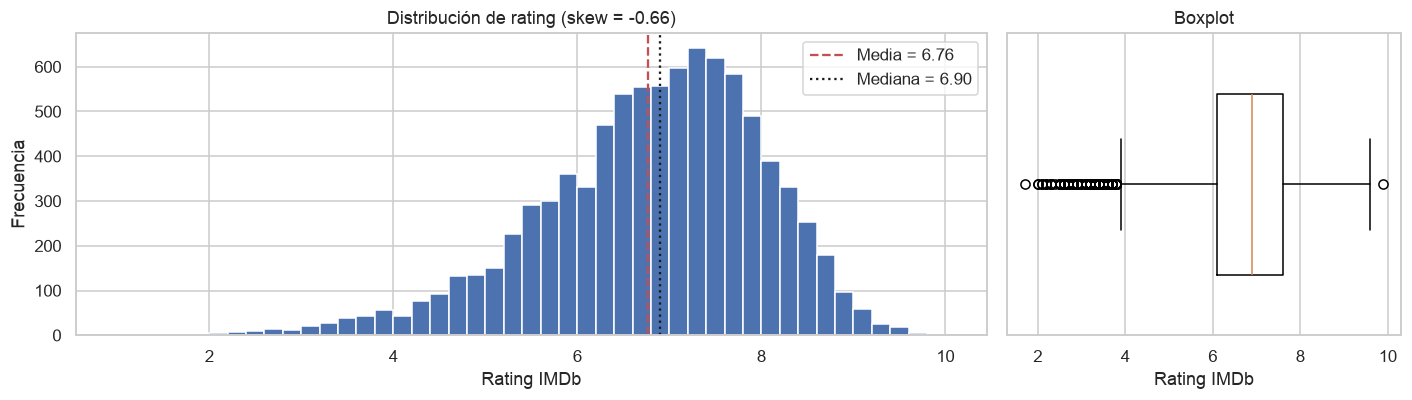

Predecir siempre 6.76 → MAE = 0.959 | RMSE = 1.215
Títulos dentro de ±1 punto de la media: 59.8%


,title,tipo_titulo,rating,votos
6633,Defcon 2012,Película,1.7,407.0
4987,Way of the Vampire,Película,2.0,1649.0
6033,Hajwala: The Missing Engine,Película,2.0,261.0
3357,Thomas & Friends: All Engines Go,Serie,2.1,604.0
3612,The Hype House,Serie,2.1,2955.0


In [14]:
rating = df['rating'].dropna()   # las filas sin rating se excluyen (ver 2.1)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [3, 1.3]})
axes[0].hist(rating, bins=np.arange(1, 10.1, 0.2), color='C0')
axes[0].axvline(rating.mean(), color='C3', ls='--', label=f'Media = {rating.mean():.2f}')
axes[0].axvline(rating.median(), color='k', ls=':', label=f'Mediana = {rating.median():.2f}')
axes[0].set_xlabel('Rating IMDb')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title(f'Distribución de rating (skew = {rating.skew():.2f})')
axes[0].legend()

axes[1].boxplot(rating, vert=False, widths=0.6)
axes[1].set_yticks([])
axes[1].set_xlabel('Rating IMDb')
axes[1].set_title('Boxplot')
plt.tight_layout()
plt.show()

# ¿Qué tan mal le iría a un "modelo" que siempre responde la media?
error_const = rating - rating.mean()
print(f'Predecir siempre {rating.mean():.2f} → MAE = {error_const.abs().mean():.3f} | '
      f'RMSE = {np.sqrt((error_const ** 2).mean()):.3f}')
print(f'Títulos dentro de ±1 punto de la media: {(error_const.abs() <= 1).mean():.1%}')
display(df.nsmallest(5, 'rating')[['title', 'tipo_titulo', 'rating', 'votos']])

**Interpretación:**

- La asimetría negativa (−0.66) indica un **sesgo a la izquierda**: la mayoría de los títulos se concentra entre 6 y 8, y una cola de pocos títulos muy mal calificados (mínimo 1.7) jala la media por debajo de la mediana.
- Un "modelo" que siempre responde la media se equivoca en promedio **±0.96 puntos (MAE)** y tiene un **RMSE de 1.21** (igual a la desviación estándar). Esta es la **vara mínima** contra la que se comparará el baseline del Paso 4: si un modelo con variables no supera este error, las variables no aportan información.

### 2.4 Distribución de las variables explicativas

#### Numéricas: la duración depende del tipo de título

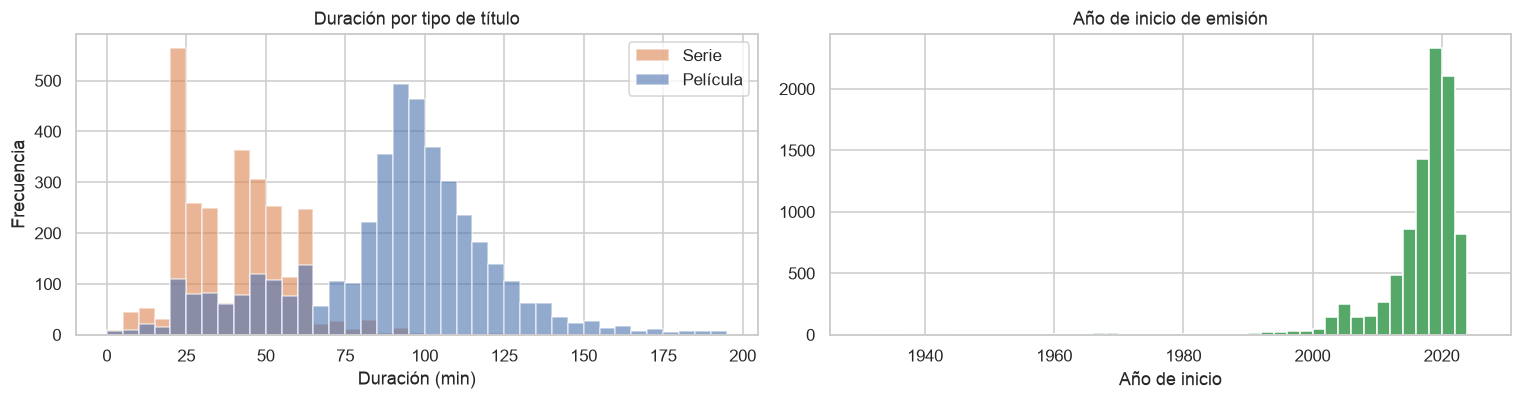

tipo_titulo
Music Video    16.5
TV Short       24.0
Serie          41.0
Video          60.0
TV Special     63.0
TV Movie       82.0
Película       94.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))

# Duración separada por tipo de título (recorte a 200 min para ver la forma)
bins = np.arange(0, 200, 5)
for tipo, color in [('Serie', 'C1'), ('Película', 'C0')]:
    axes[0].hist(df.loc[df['tipo_titulo'] == tipo, 'duracion_min'].dropna(),
                 bins=bins, alpha=0.6, label=tipo, color=color)
axes[0].set_xlabel('Duración (min)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Duración por tipo de título')
axes[0].legend()

# Año de inicio
axes[1].hist(df['anio_inicio'].dropna(), bins=np.arange(1930, 2027, 2), color='C2')
axes[1].set_xlabel('Año de inicio')
axes[1].set_title('Año de inicio de emisión')
plt.tight_layout()
plt.show()

print(df.groupby('tipo_titulo')['duracion_min'].median().dropna().sort_values().to_string())

**Interpretación:**

- Los tres picos de `duracion_min` corresponden a **poblaciones distintas**: series de media hora (sitcoms, animación y anime, ~22–25 min), series de una hora (~45–60 min) y películas (~90–100 min). La variable sola es ambigua; **necesita acompañarse del tipo de título**, y la imputación de faltantes debería hacerse **por grupo** (Paso 3).
- `anio_inicio` está fuertemente concentrado en títulos recientes (mediana 2018). El dataset **no es una muestra aleatoria de IMDb**: hay **sesgo de muestreo** hacia contenido de 2010 en adelante, por lo que el modelo no debería usarse para títulos clásicos.

#### Categóricas: tipo de título, clasificación y géneros

Géneros individuales: 27 | Combinaciones distintas en el original: 569


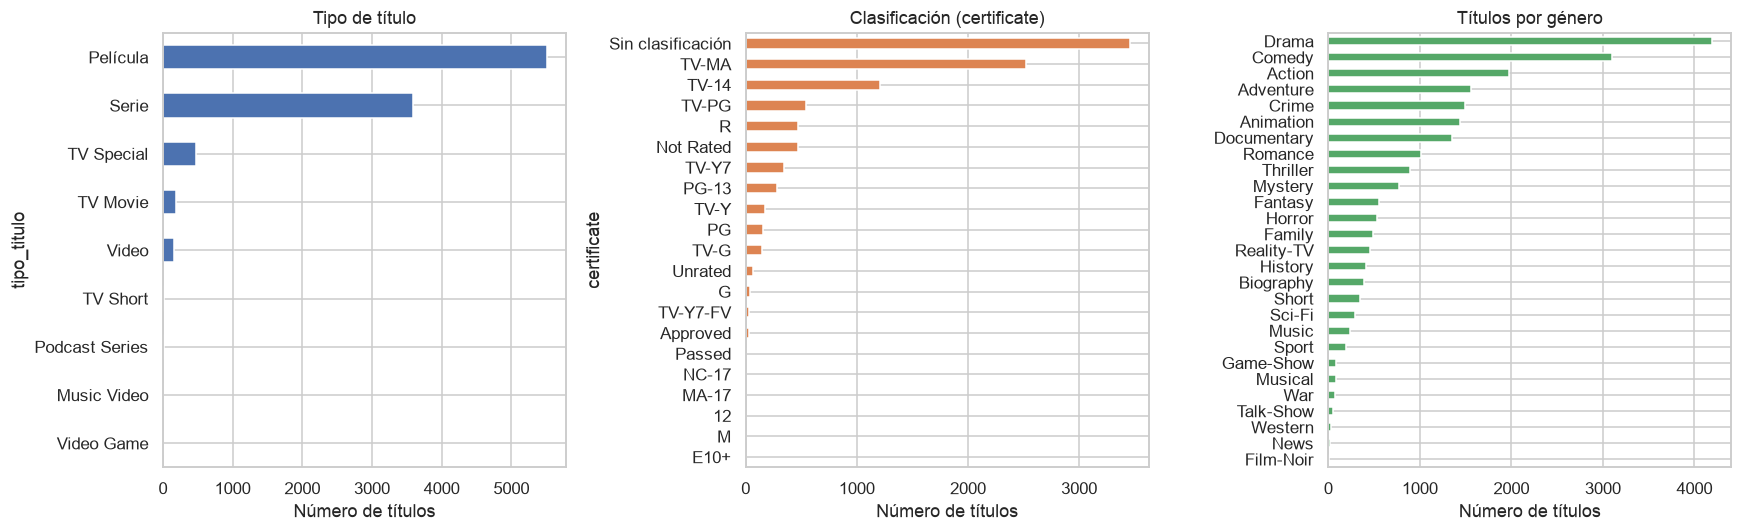

In [16]:
# Representación multi-hot de géneros: una columna binaria por género (un título puede tener hasta 3)
generos = df['genre'].str.get_dummies(sep=', ')
print(f'Géneros individuales: {generos.shape[1]} | Combinaciones distintas en el original: {df["genre"].nunique()}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

df['tipo_titulo'].value_counts().plot.barh(ax=axes[0], color='C0')
axes[0].invert_yaxis()
axes[0].set_title('Tipo de título')

# Los faltantes de certificate se muestran como su propia categoría
df['certificate'].fillna('Sin clasificación').value_counts().plot.barh(ax=axes[1], color='C1')
axes[1].invert_yaxis()
axes[1].set_title('Clasificación (certificate)')

generos.sum().sort_values().plot.barh(ax=axes[2], color='C2')
axes[2].set_title('Títulos por género')
for ax in axes:
    ax.set_xlabel('Número de títulos')
plt.tight_layout()
plt.show()

**Interpretación:**

- **Tipo de título:** predominan películas (~55 %) y series (~36 %); el resto son especiales, telefilmes y videos con pocas observaciones.
- **Clasificación:** "Sin clasificación" es la categoría más grande (35 %), seguida de `TV-MA` y `TV-14`. Hay categorías con 1–6 registros (`MA-17`, `12`, `M`, `E10+`, `Passed`, `NC-17`) que deberán agruparse en una categoría "Otra" para no crear columnas casi vacías.
- **Géneros:** con la codificación multi-hot, las 569 combinaciones se reducen a **27 columnas binarias**. Drama y Comedy dominan; géneros como `News`, `Western` o `Game-Show` son poco frecuentes.

### 2.5 Relaciones con la variable objetivo

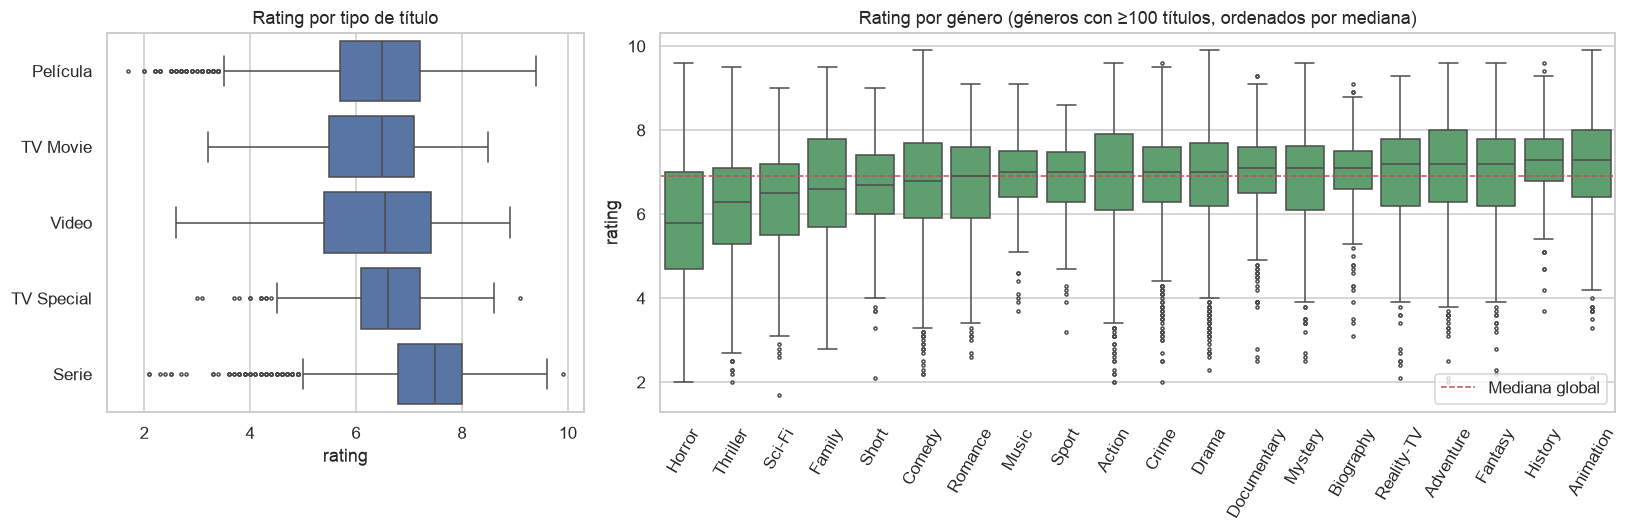

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [1, 2]})

# Rating por tipo de título (solo tipos con al menos 50 títulos calificados)
tipos_ok = df['tipo_titulo'].value_counts().loc[lambda s: s >= 50].index
orden_tipo = df[df['tipo_titulo'].isin(tipos_ok)].groupby('tipo_titulo')['rating'].median().sort_values().index
sns.boxplot(data=df[df['tipo_titulo'].isin(tipos_ok)], x='rating', y='tipo_titulo',
            order=orden_tipo, ax=axes[0], color='C0', fliersize=2)
axes[0].set_title('Rating por tipo de título')
axes[0].set_ylabel('')

# Rating por género: se "explota" el dataset para que cada título aparezca una vez por género
# reset_index: explode repite el índice original y seaborn requiere índices únicos
por_genero = df.assign(genero=df['genre'].str.split(', ')).explode('genero').reset_index(drop=True)
conteo = por_genero['genero'].value_counts()
por_genero = por_genero[por_genero['genero'].isin(conteo[conteo >= 100].index)]
orden_gen = por_genero.groupby('genero')['rating'].median().sort_values().index
sns.boxplot(data=por_genero, x='genero', y='rating', order=orden_gen, ax=axes[1], color='C2', fliersize=2)
axes[1].axhline(rating.median(), color='C3', ls='--', lw=1, label='Mediana global')
axes[1].tick_params(axis='x', rotation=60)
axes[1].set_title('Rating por género (géneros con ≥100 títulos, ordenados por mediana)')
axes[1].set_xlabel('')
axes[1].legend()
plt.tight_layout()
plt.show()

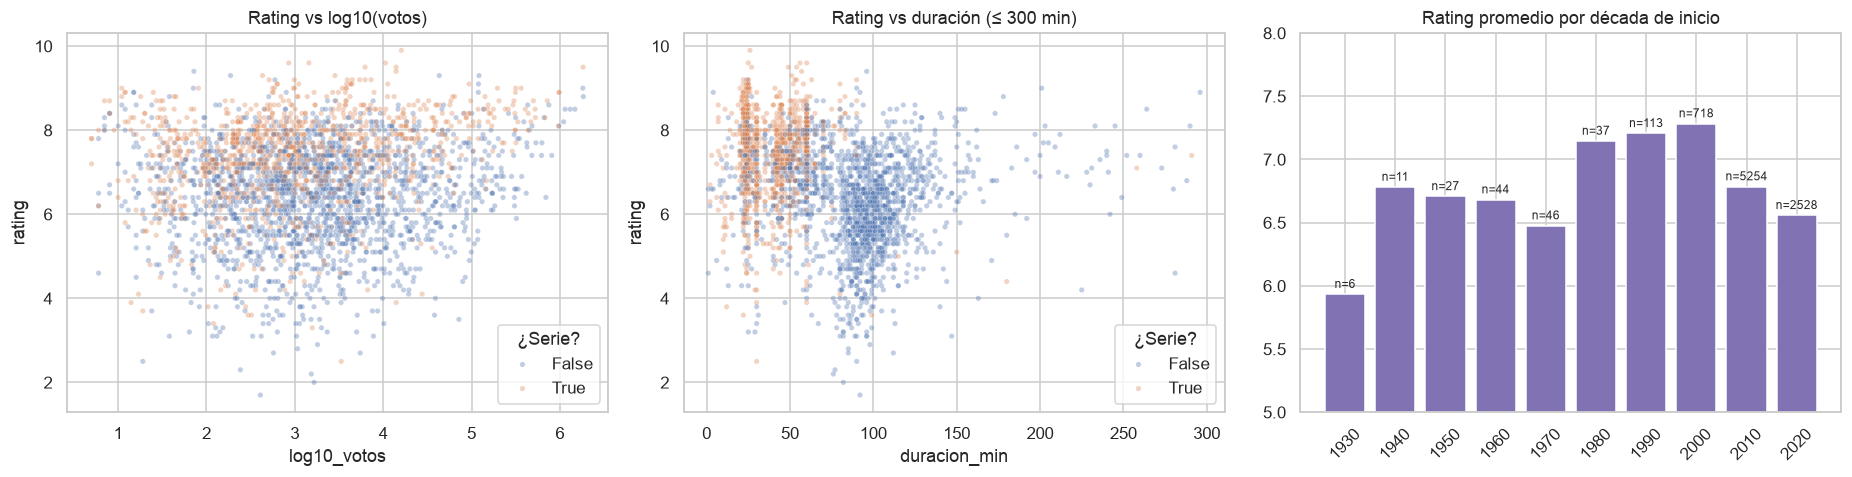

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Rating vs popularidad (log10 de votos), coloreado por serie/película
muestra = df.dropna(subset=['rating']).sample(3000, random_state=RANDOM_STATE)
sns.scatterplot(data=muestra, x='log10_votos', y='rating', hue='es_serie',
                alpha=0.35, s=12, ax=axes[0])
axes[0].set_title('Rating vs log10(votos)')
axes[0].legend(title='¿Serie?')

# Rating vs duración (≤300 min), coloreado por serie/película
sns.scatterplot(data=muestra[muestra['duracion_min'] <= 300], x='duracion_min', y='rating',
                hue='es_serie', alpha=0.35, s=12, ax=axes[1])
axes[1].set_title('Rating vs duración (≤ 300 min)')
axes[1].legend(title='¿Serie?')

# Rating promedio por década de inicio, con el número de títulos
decada = (df['anio_inicio'] // 10 * 10).rename('decada')
por_decada = df.groupby(decada)['rating'].agg(['mean', 'count']).dropna()
axes[2].bar(por_decada.index.astype(int).astype(str), por_decada['mean'], color='C4')
for i, (m, n) in enumerate(zip(por_decada['mean'], por_decada['count'])):
    axes[2].text(i, m + 0.05, f'n={n}', ha='center', fontsize=8)
axes[2].set_ylim(5, 8)
axes[2].set_title('Rating promedio por década de inicio')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Interpretación:**

- **Tipo de título** es la variable con la diferencia más clara: las series tienen una mediana cercana a 7.5, contra ~6.5 de las películas.
- **Género:** Horror y Thriller quedan claramente por debajo de la mediana global; History, Animation y Documentary por encima. Los géneros aportan señal, aunque con mucha variabilidad dentro de cada uno.
- **Votos:** la relación es débil en el rango medio, pero los títulos más populares (> 10⁵ votos) casi nunca tienen calificaciones bajas.
- **Década:** las décadas previas a 1980 tienen menos de 50 títulos cada una, demasiado pocos para sacar conclusiones. Entre 1980 y 2009 el promedio es más alto (~7.1–7.3) que en 2010–2020 (~6.6–6.8), posiblemente porque los títulos antiguos que llegan a la lista son los que siguen siendo populares. Esto refuerza el sesgo de muestreo descrito en 2.4.

### 2.6 Correlaciones y una variable de confusión

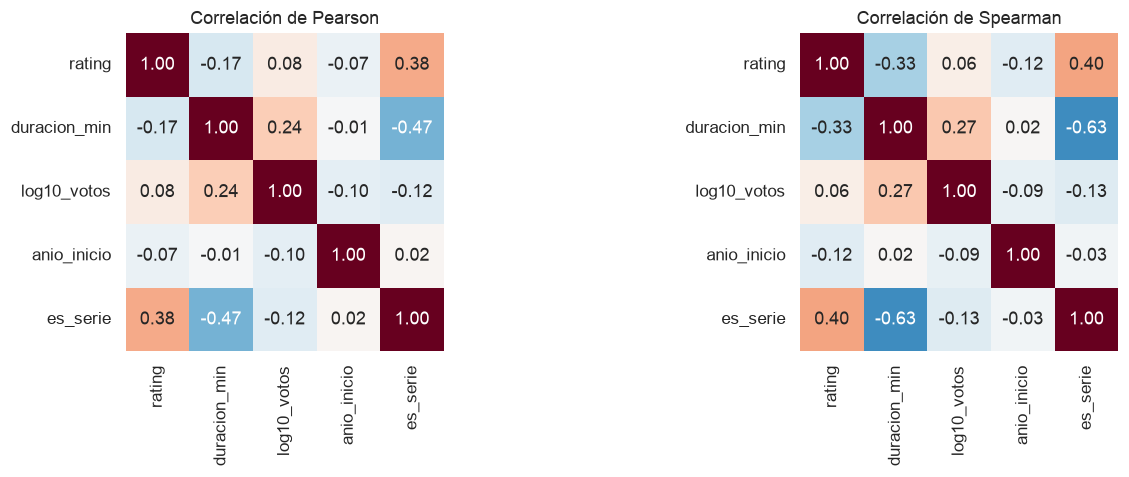

In [19]:
# Pearson (relación lineal) vs Spearman (relación monótona, basada en rangos)
vars_corr = ['rating', 'duracion_min', 'log10_votos', 'anio_inicio', 'es_serie']
datos_corr = df[vars_corr].astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metodo in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(datos_corr.corr(method=metodo), annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
    ax.set_title(f'Correlación de {metodo.capitalize()}')
plt.tight_layout()
plt.show()

In [20]:
# ¿"Entre más largo, peor calificado"? Se compara la correlación global contra la correlación
# dentro de cada tipo de título, y el efecto de los valores extremos sobre Pearson
filas = {
    'Global': df,
    'Global sin duración > 300 min': df[df['duracion_min'] <= 300],
    'Solo series': df[df['tipo_titulo'] == 'Serie'],
    'Solo películas': df[df['tipo_titulo'] == 'Película'],
}
pd.DataFrame({
    nombre: {
        'Pearson': d['rating'].corr(d['duracion_min']),
        'Spearman': d['rating'].corr(d['duracion_min'], method='spearman'),
        'n': d[['rating', 'duracion_min']].dropna().shape[0],
    } for nombre, d in filas.items()
}).T.round(2)

,Pearson,Spearman,n
Global,-0.17,-0.33,7680.0
Global sin duración > 300 min,-0.27,-0.35,7623.0
Solo series,0.06,0.10,2641.0
Solo películas,0.04,-0.07,4346.0


**Interpretación:**

- **Pearson vs Spearman:** Pearson mide relación lineal y es sensible a valores extremos; Spearman trabaja con rangos y es robusto a asimetría y outliers. Al quitar las duraciones mayores a 300 min, Pearson pasa de −0.17 a −0.27, acercándose a Spearman: los outliers estaban atenuando la relación lineal.
- **Variable de confusión:** dentro de las series la correlación duración–rating es ~0.06 y dentro de las películas ~0.04, es decir, **prácticamente nula**. La correlación negativa global aparece porque `tipo_titulo` influye en ambas variables: las series son **más cortas y mejor calificadas**. La conclusión "entre más largo, peor calificado" sería errónea; **correlación no implica causalidad**.
- La variable más asociada con `rating` es `es_serie` (r ≈ 0.38–0.40); las numéricas continuas tienen correlaciones débiles (|r| ≤ 0.33). Se espera que un modelo lineal simple tenga un desempeño **modesto**, lo cual es aceptable para un baseline.

### 2.7 Resumen del EDA e implicaciones

| Hallazgo | Implicación para la limpieza y el modelo |
|---|---|
| `duration`, `votes`, `year` llegaron como texto | Ya convertidas con `convertir_tipos()`; se reutiliza en el pipeline |
| 1,173 filas sin `rating` (títulos no estrenados) | Se eliminan del conjunto de modelado; no se imputa la variable objetivo |
| `duracion_min` mezcla poblaciones (episodio vs. película vs. total de miniserie) | Imputar faltantes **por tipo de título**; revisar outliers > 300 min |
| `votos` con cola larga a la derecha | Usar `log10_votos`; no eliminar valores altos (son legítimos) |
| `rating` con sesgo a la izquierda; MAE de predecir la media = 0.96 | Métricas MAE/RMSE; el `DummyRegressor` es la referencia a superar |
| `tipo_titulo` es la variable con mayor separación y es confusora de la duración | Incluirla como variable explicativa |
| 569 combinaciones de género → 27 géneros | Codificación **multi-hot** |
| `certificate`: 35 % faltante (informativo) y categorías raras | Faltante como categoría "Sin clasificación"; agrupar raras en "Otra" |
| Dataset concentrado en títulos recientes | Limitación documentada: sesgo de muestreo |

---
## Del EDA al código

Las decisiones anteriores se implementaron en el paquete `imdb_rating`:

| Decisión del EDA | Implementación |
|---|---|
| Conversión de tipos | `dataset.convertir_tipos` |
| Una fila por título, sin `rating`/`genre` faltante, recorte de duración a 300 min, `log10_votos`, agrupación de categorías, multi-hot de géneros | `dataset.limpiar` (reglas en `config.py`) |
| Imputar duración con la mediana **por tipo de título**, ajustada solo con entrenamiento | `features.ImputadorMedianaPorGrupo` dentro del `Pipeline` |
| Split 80/20 estratificado por `tipo_titulo` | `features.split_data` |
| Modelo y registro de experimentos | `modeling/train.py` (Random Forest + MLflow) |

Para generar el dataset limpio y entrenar:

```bash
python -m imdb_rating.dataset
python -m imdb_rating.modeling.train --help
```